<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Decision_Tree/diabetes_decision_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv'
df = pd.read_csv(url)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
print('Rows, columns:', df.shape)
print()
print('Missing values (NaN) per column:')
print(df.isnull().sum())
print()
print('Class counts (0 = no diabetes, 1 = diabetes):')
print(df['Outcome'].value_counts())
print('Share with diabetes:', round(df['Outcome'].mean(), 3))
print()

fake_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print('Number of zeros in columns where zero is impossible:')
print((df[fake_zero_cols] == 0).sum())

Rows, columns: (768, 9)

Missing values (NaN) per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class counts (0 = no diabetes, 1 = diabetes):
Outcome
0    500
1    268
Name: count, dtype: int64
Share with diabetes: 0.349

Number of zeros in columns where zero is impossible:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


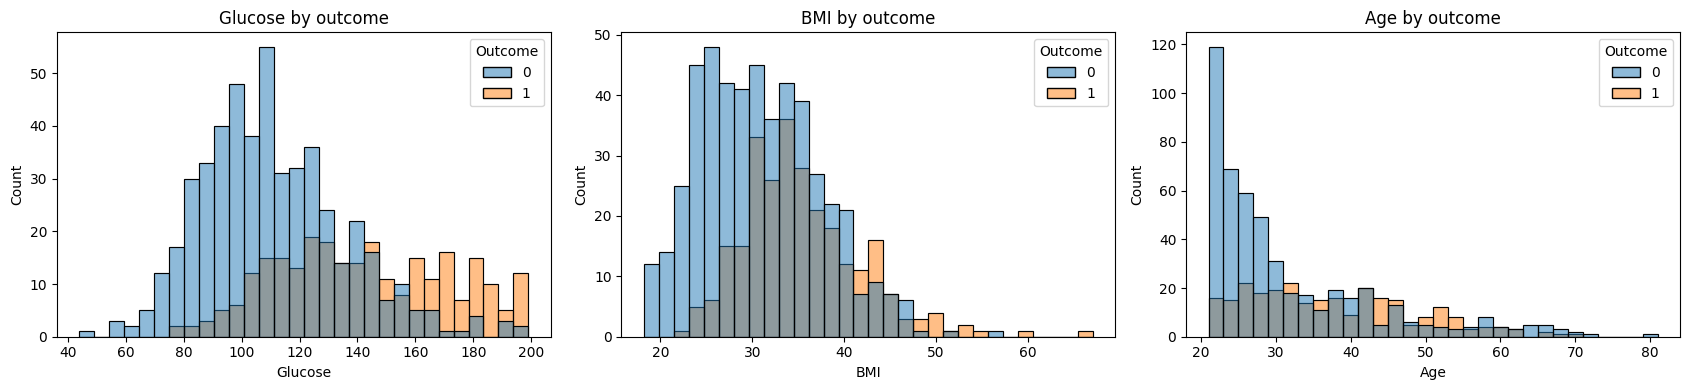

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, col in zip(axes, ['Glucose', 'BMI', 'Age']):
    plot_df = df[df[col] > 0]
    sns.histplot(data=plot_df, x=col, hue='Outcome', bins=30, multiple='layer', alpha=0.5, ax=ax)
    ax.set_title(col + ' by outcome')

plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

fake_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

X = df.drop(columns='Outcome')   # features
y = df['Outcome']                # label

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

# impossible zeros -> missing
X_train[fake_zero_cols] = X_train[fake_zero_cols].replace(0, np.nan)
X_test[fake_zero_cols] = X_test[fake_zero_cols].replace(0, np.nan)

# fill with the TRAINING medians
medians = X_train[fake_zero_cols].median()
X_train[fake_zero_cols] = X_train[fake_zero_cols].fillna(medians)
X_test[fake_zero_cols] = X_test[fake_zero_cols].fillna(medians)

print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Missing values left:', int(X_train.isnull().sum().sum() + X_test.isnull().sum().sum()))
print()
print('Medians used to fill the gaps:')
print(medians.round(1).to_string())

Training rows: 614 | Test rows: 154
Missing values left: 0

Medians used to fill the gaps:
Glucose          117.0
BloodPressure     72.0
SkinThickness     29.0
Insulin          125.0
BMI               32.4


In [5]:
def gini(labels):
    # 0 = perfectly pure group, 0.5 = completely mixed (two classes)
    if len(labels) == 0:
        return 0.0
    p1 = np.mean(labels)
    return 1 - p1 ** 2 - (1 - p1) ** 2


y_values = y_train.values
print('Gini of the whole training set:', round(gini(y_values), 3))

best = {'gini': 1.0}
for feature in X_train.columns:
    column = X_train[feature].values
    unique_values = np.sort(np.unique(column))
    thresholds = (unique_values[:-1] + unique_values[1:]) / 2     # midpoints between neighbours
    for thr in thresholds:
        left = y_values[column <= thr]
        right = y_values[column > thr]
        weighted = (len(left) * gini(left) + len(right) * gini(right)) / len(y_values)
        if weighted < best['gini']:
            best = {'gini': weighted, 'feature': feature, 'threshold': thr}

print()
print('Best first question found by hand:')
print('   is', best['feature'], '<=', round(best['threshold'], 2), '?')
print('   weighted Gini after the split:', round(best['gini'], 3))

Gini of the whole training set: 0.454

Best first question found by hand:
   is Glucose <= 154.5 ?
   weighted Gini after the split: 0.362


In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
deep_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

print('Baseline accuracy (always "no diabetes"):', round(accuracy_score(y_test, baseline.predict(X_test)), 3))
print()
print('Unrestricted tree, training accuracy:', round(deep_tree.score(X_train, y_train), 3))
print('Unrestricted tree, test accuracy    :', round(deep_tree.score(X_test, y_test), 3))
print()
print('Tree depth:', deep_tree.get_depth())
print('Leaves    :', deep_tree.get_n_leaves(), '(for only', len(X_train), 'training rows)')

Baseline accuracy (always "no diabetes"): 0.649

Unrestricted tree, training accuracy: 1.0
Unrestricted tree, test accuracy    : 0.682

Tree depth: 14
Leaves    : 111 (for only 614 training rows)


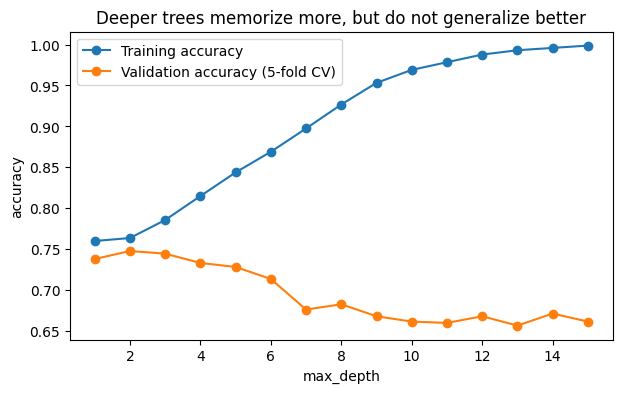

Depth with the best validation accuracy: 2 -> 0.748


In [7]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

depths = list(range(1, 16))
train_scores, val_scores = [], []
for d in depths:
    result = cross_validate(
        DecisionTreeClassifier(max_depth=d, random_state=42),
        X_train, y_train, cv=cv, scoring='accuracy', return_train_score=True
    )
    train_scores.append(result['train_score'].mean())
    val_scores.append(result['test_score'].mean())

plt.figure(figsize=(7, 4))
plt.plot(depths, train_scores, marker='o', label='Training accuracy')
plt.plot(depths, val_scores, marker='o', label='Validation accuracy (5-fold CV)')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.title('Deeper trees memorize more, but do not generalize better')
plt.legend()
plt.show()

best_depth = depths[int(np.argmax(val_scores))]
print('Depth with the best validation accuracy:', best_depth, '->', round(max(val_scores), 3))

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy'],
    'ccp_alpha': [0.0, 0.002, 0.005, 0.01],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid, cv=cv, scoring='accuracy'
)
grid.fit(X_train, y_train)

tuned = grid.best_estimator_
print('Best settings   :', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))
print('Tuned tree depth:', tuned.get_depth(), '| leaves:', tuned.get_n_leaves())

Best settings   : {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 10}
Best CV accuracy: 0.749
Tuned tree depth: 2 | leaves: 4


                               train accuracy  test accuracy
Baseline (always no diabetes)           0.651          0.649
Unrestricted tree                       1.000          0.682
Tuned tree                              0.761          0.695

ROC-AUC of the tuned tree (test): 0.701

              precision    recall  f1-score   support

 No diabetes       0.70      0.92      0.80       100
    Diabetes       0.65      0.28      0.39        54

    accuracy                           0.69       154
   macro avg       0.68      0.60      0.59       154
weighted avg       0.68      0.69      0.65       154



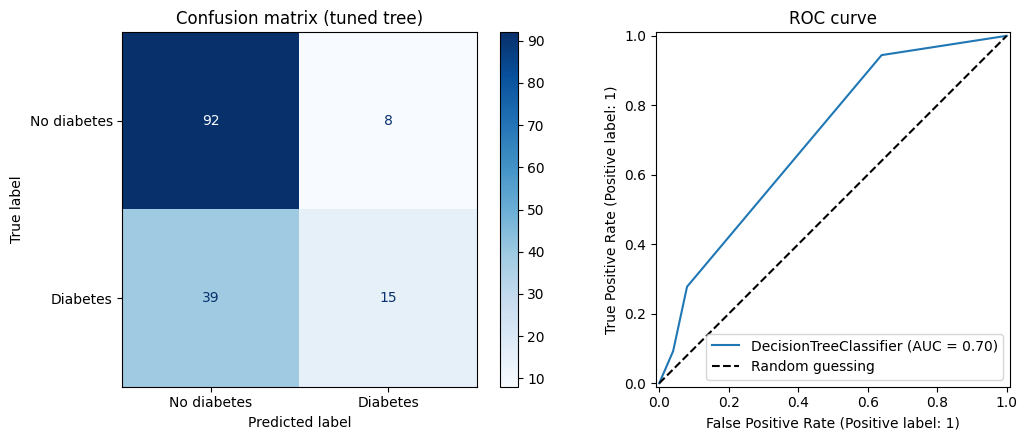

In [9]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

pred = tuned.predict(X_test)
proba = tuned.predict_proba(X_test)[:, 1]

summary = pd.DataFrame({
    'train accuracy': [baseline.score(X_train, y_train), deep_tree.score(X_train, y_train), tuned.score(X_train, y_train)],
    'test accuracy': [baseline.score(X_test, y_test), deep_tree.score(X_test, y_test), tuned.score(X_test, y_test)],
}, index=['Baseline (always no diabetes)', 'Unrestricted tree', 'Tuned tree'])
print(summary.round(3).to_string())
print()
print('ROC-AUC of the tuned tree (test):', round(roc_auc_score(y_test, proba), 3))
print()
print(classification_report(y_test, pred, target_names=['No diabetes', 'Diabetes']))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_estimator(
    tuned, X_test, y_test, display_labels=['No diabetes', 'Diabetes'], cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion matrix (tuned tree)')

RocCurveDisplay.from_estimator(tuned, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guessing')
axes[1].legend()
axes[1].set_title('ROC curve')

plt.tight_layout()
plt.show()

Small tree (depth 3) test accuracy: 0.695
Tuned tree           test accuracy: 0.695


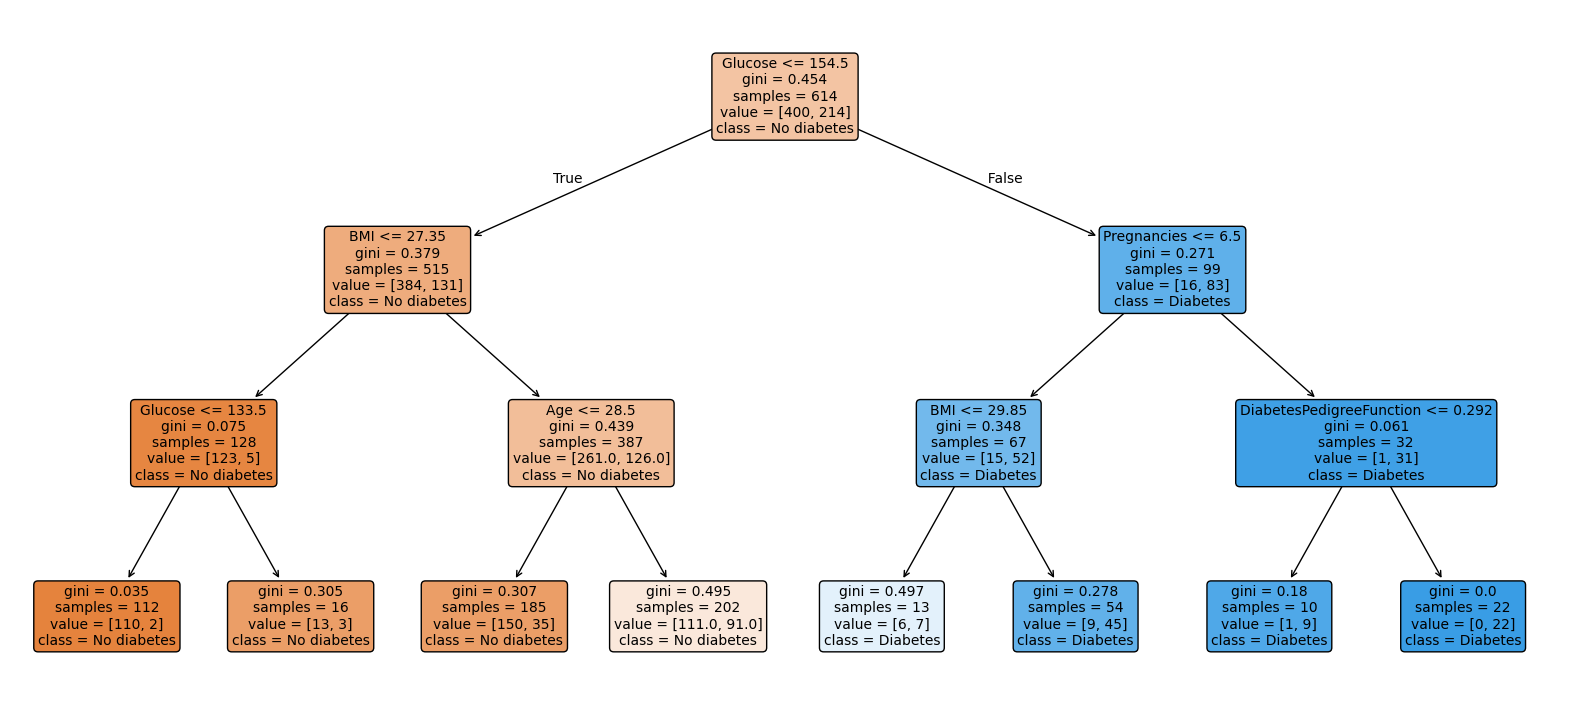

In [10]:
from sklearn.tree import plot_tree, export_text

small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=42)
small_tree.fit(X_train, y_train)

print('Small tree (depth 3) test accuracy:', round(small_tree.score(X_test, y_test), 3))
print('Tuned tree           test accuracy:', round(tuned.score(X_test, y_test), 3))

plt.figure(figsize=(20, 9))
plot_tree(
    small_tree,
    feature_names=list(X_train.columns),
    class_names=['No diabetes', 'Diabetes'],
    filled=True, rounded=True, fontsize=10,
)
plt.show()

In [11]:
print(export_text(small_tree, feature_names=list(X_train.columns)))

root_feature = X_train.columns[deep_tree.tree_.feature[0]]
root_threshold = deep_tree.tree_.threshold[0]
print('First question chosen by scikit-learn (unrestricted tree):', root_feature, '<=', round(root_threshold, 2))
print('First question found by hand in Step 6                    :', best['feature'], '<=', round(best['threshold'], 2))

|--- Glucose <= 154.50
|   |--- BMI <= 27.35
|   |   |--- Glucose <= 133.50
|   |   |   |--- class: 0
|   |   |--- Glucose >  133.50
|   |   |   |--- class: 0
|   |--- BMI >  27.35
|   |   |--- Age <= 28.50
|   |   |   |--- class: 0
|   |   |--- Age >  28.50
|   |   |   |--- class: 0
|--- Glucose >  154.50
|   |--- Pregnancies <= 6.50
|   |   |--- BMI <= 29.85
|   |   |   |--- class: 1
|   |   |--- BMI >  29.85
|   |   |   |--- class: 1
|   |--- Pregnancies >  6.50
|   |   |--- DiabetesPedigreeFunction <= 0.29
|   |   |   |--- class: 1
|   |   |--- DiabetesPedigreeFunction >  0.29
|   |   |   |--- class: 1

First question chosen by scikit-learn (unrestricted tree): Glucose <= 154.5
First question found by hand in Step 6                    : Glucose <= 154.5


Glucose                     0.765
BMI                         0.213
Pregnancies                 0.022
BloodPressure               0.000
SkinThickness               0.000
Insulin                     0.000
DiabetesPedigreeFunction    0.000
Age                         0.000


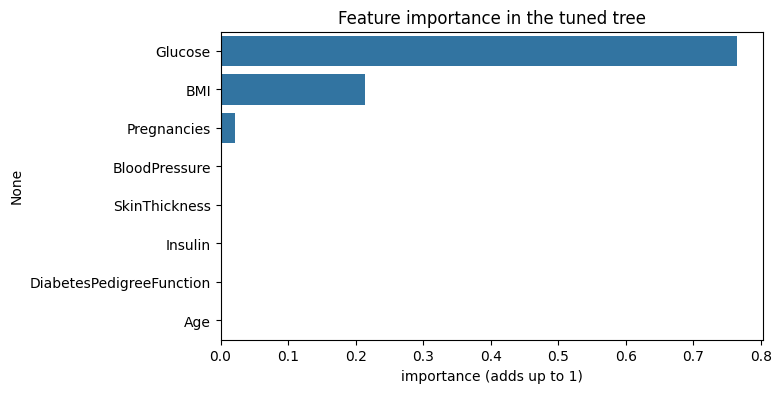

In [12]:
importance = pd.Series(tuned.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance.round(3).to_string())

plt.figure(figsize=(7, 4))
sns.barplot(x=importance.values, y=importance.index)
plt.xlabel('importance (adds up to 1)')
plt.title('Feature importance in the tuned tree')
plt.show()

In [13]:
def explain_path(model, row):
    # print every question the patient answered on the way to a leaf
    tree = model.tree_
    path_nodes = model.decision_path(row).indices
    leaf = model.apply(row)[0]
    for node in path_nodes:
        if node == leaf:
            continue
        feature_index = tree.feature[node]
        name = row.columns[feature_index]
        value = row.iloc[0, feature_index]
        threshold = tree.threshold[node]
        answer = '<=' if value <= threshold else '>'
        print(f'   {name} = {value:g}  is {answer}  {threshold:.2f}')


def predict_patient(model, pregnancies, glucose, blood_pressure, skin_thickness,
                    insulin, bmi, pedigree, age):
    row = pd.DataFrame([{
        'Pregnancies': pregnancies,
        'Glucose': glucose,
        'BloodPressure': blood_pressure,
        'SkinThickness': skin_thickness,
        'Insulin': insulin,
        'BMI': bmi,
        'DiabetesPedigreeFunction': pedigree,
        'Age': age,
    }])[X_train.columns]

    p = model.predict_proba(row)[0, 1]
    print('Prediction:', 'DIABETES' if p >= 0.5 else 'NO DIABETES', f'(probability of diabetes = {p:.2f})')
    print('Path through the tree:')
    explain_path(model, row)


print('Patient A: 28 years old, normal glucose and BMI')
predict_patient(tuned, pregnancies=1, glucose=95, blood_pressure=70, skin_thickness=25,
                insulin=90, bmi=24.0, pedigree=0.3, age=28)

print()
print('Patient B: 52 years old, high glucose and BMI')
predict_patient(tuned, pregnancies=4, glucose=170, blood_pressure=80, skin_thickness=35,
                insulin=200, bmi=38.0, pedigree=0.9, age=52)

Patient A: 28 years old, normal glucose and BMI
Prediction: NO DIABETES (probability of diabetes = 0.04)
Path through the tree:
   Glucose = 95  is <=  154.50
   BMI = 24  is <=  27.35

Patient B: 52 years old, high glucose and BMI
Prediction: DIABETES (probability of diabetes = 0.78)
Path through the tree:
   Glucose = 170  is >  154.50
   Pregnancies = 4  is <=  6.50
